# Laboratorio 2
## Pipeline de Machine Learning para Clasificación de Sentimientos con Transformers

En este laboratorio, realizarás una clasificación de sentimiento de reseñas de películas mediante el modelo de transformadores. Como parte de este laboratorio, implementarás un análisis exploratorio de datos para obtener conocimientos sobre la data y su distribución. Posteriormente, los modelos requieren un tokenizer que implementarás personalmente. A continuación, programarás el elemento integral del modelo de transformador, la Mecánica de Atención. Finalmente, combinarás todo y entrenarás al modelo en la tarea de clasificación binaria.

## Tutorial: Cómo activar la GPU gratuita en Google Colab

Para este laboratorio, se recomienda usar la GPU gratuita de Google Colab para acelerar el entrenamiento. Sigue estos pasos:

### Pasos para activar la GPU:

1. **Abre tu notebook en Google Colab**
   - Sube este archivo a Google Drive
   - Haz clic derecho sobre el archivo → "Abrir con" → "Google Colaboratory"

2. **Cambia el tipo de entorno de ejecución**
   - En el menú superior, ve a: **Entorno de ejecución** → **Cambiar tipo de entorno de ejecución**
   - (O en inglés: **Runtime** → **Change runtime type**)

3. **Selecciona la GPU**
   - En "Acelerador por hardware" (Hardware accelerator), selecciona T4 GPU
   - Haz clic en **Guardar** (Save)

4. **Verifica que la GPU esté activa**
   - Ejecuta la siguiente celda para confirmar que tienes acceso a la GPU

### Notas importantes:
- La GPU gratuita tiene límites de uso diario (aproximadamente 12-15 horas por día)
- Si se desconecta, deberás volver a ejecutar todas las celdas
- Guarda tu progreso frecuentemente

In [1]:
# Verificar que la GPU está disponible
import torch
if torch.cuda.is_available():
    print(f"✓ GPU detectada: {torch.cuda.get_device_name(0)}")
    print(f"  Memoria total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("✗ No se detectó GPU. Por favor, activa la GPU siguiendo los pasos del tutorial anterior.")

✓ GPU detectada: Tesla T4
  Memoria total: 15.64 GB


## Instalación de Dependencias

Primero, instalaremos las bibliotecas necesarias para este laboratorio.

In [2]:
!pip install -q datasets

## Imports y Setup Inicial

Importamos todas las bibliotecas necesarias y configuramos las semillas aleatorias para reproducibilidad.

In [3]:
# Initial Setup
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, random_split
import os
import random
import math
import copy
import time
import numpy as np
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Set random seeds for reproducibility
random_seed = 48

os.environ['PYTHONHASHSEED'] = str(random_seed)
random.seed(random_seed)
np.random.seed(random_seed)

torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(random_seed)
    torch.cuda.manual_seed_all(random_seed)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Check if CUDA is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## Análisis Exploratorio de Datos (EDA)

### 1.- Carga de Datos

Cargaremos el dataset IMDB que contiene reseñas de películas con sentimientos positivos y negativos.

In [4]:
# Load the dataset
dataset = load_dataset('stanfordnlp/imdb')

texts = list(dataset['train']['text']) + list(dataset['test']['text'])
labels = list(dataset['train']['label']) + list(dataset['test']['label'])

print(f"Total de textos: {len(texts)}")
print(f"Etiquetas únicas: {np.unique(labels)}")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Total de textos: 50000
Etiquetas únicas: [0 1]


### 2.- Visualización de Distribuciones

Analizaremos la distribución de longitudes de las reseñas y la distribución de las etiquetas (positivo/negativo).

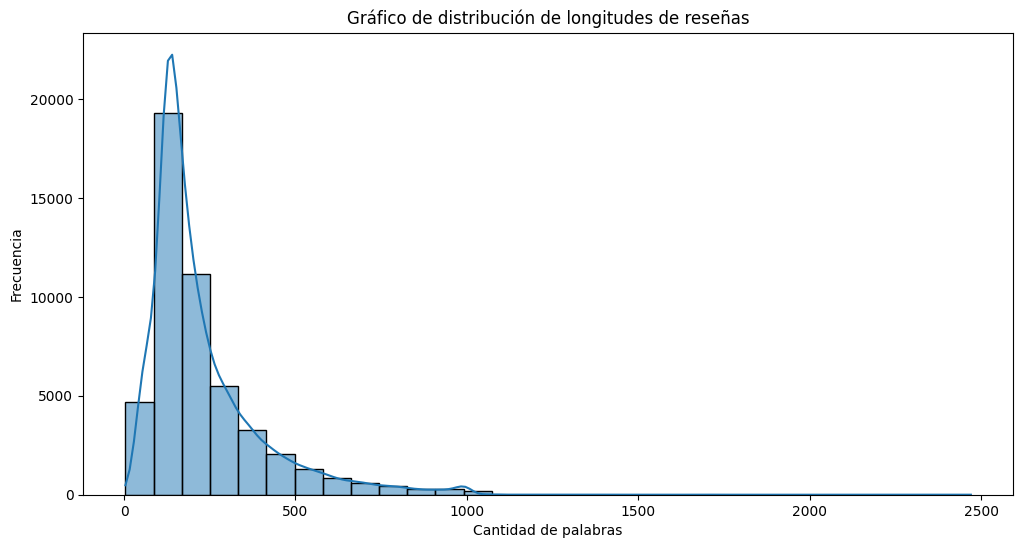

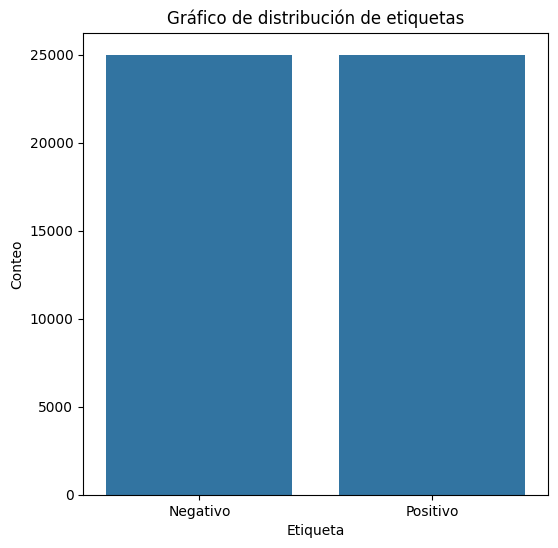

Promedio de longitud de reseñas positivas: 232.85 palabras
Promedio de longitud de reseñas negativas: 229.46 palabras


In [5]:
def word_count(text):
    return len(text.split())

review_lengths = [word_count(text) for text in texts]

# Plot the distribution of review lengths
plt.figure(figsize=(12, 6))
sns.histplot(review_lengths, bins=30, kde=True)
plt.title('Gráfico de distribución de longitudes de reseñas')
plt.xlabel('Cantidad de palabras')
plt.ylabel('Frecuencia')
plt.show()

# Plot the distribution of labels
label_counts = Counter(labels)
plt.figure(figsize=(6, 6))
sns.barplot(x=list(label_counts.keys()), y=list(label_counts.values()))
plt.title('Gráfico de distribución de etiquetas')
plt.xlabel('Etiqueta')
plt.ylabel('Conteo')
plt.xticks(ticks=[0, 1], labels=['Negativo', 'Positivo'])
plt.show()

average_positive_length = np.mean([review_lengths[i] for i in range(len(labels)) if labels[i] == 1])
average_negative_length = np.mean([review_lengths[i] for i in range(len(labels)) if labels[i] == 0])

print(f"Promedio de longitud de reseñas positivas: {average_positive_length:.2f} palabras")
print(f"Promedio de longitud de reseñas negativas: {average_negative_length:.2f} palabras")

**Interpretación.** La distribución de longitudes está sesgada a la derecha: la mayoría de las reseñas son cortas,
con una cola de reseñas muy largas. Las etiquetas están balanceadas y el largo promedio casi no cambia entre
positivas (232,9 palabras) y negativas (229,5), así que el largo no sirve para predecir el sentimiento.

## Tareas

### 1: Implementación del Tokenizador

- [ ] Ampliar el tokenizador para que construya un vocabulario de 30.000 palabras y fragmentos de palabra (libro capítulo 12.5).
- [ ] Mostrar el tamaño del vocabulario a lo largo de las iteraciones del algoritmo.

**Algoritmo (Byte Pair Encoding).** Se parte de un vocabulario con todos los caracteres más el marcador de fin de
palabra `_`. En cada iteración se cuentan los pares de símbolos adyacentes (ponderados por la frecuencia de la
palabra), se fusiona el par más frecuente y el nuevo fragmento se agrega al vocabulario, hasta llegar a 30.000.


In [7]:
import re
from collections import Counter, defaultdict

class SimpleTokenizer:
    def __init__(self, target_vocab_size=30000):
        self.target_vocab_size = target_vocab_size
        self.special_tokens = {'[PAD]': 0, '[UNK]': 1}
        self.vocab = {'[PAD]': 0, '[UNK]': 1}
        self.reverse_vocab = {0: '[PAD]', 1: '[UNK]'}
        self.merges = {}
        self.merge_ranks = {}  # par -> orden en que se aprendió la fusión
        self.history = []      # (iteración, tamaño del vocabulario, frecuencia del par fusionado)
        self.cache = {}        # palabra -> fragmentos ya calculados

    def tokenize(self, text):
        # Minúsculas, sin los saltos de línea HTML "<br />" y con la puntuación separada de las palabras,
        # para que "good", "good." y "good," compartan el mismo fragmento "good_".
        text = re.sub(r'<br\s*/?>', ' ', text.lower())
        return re.findall(r"\w+(?:'\w+)?|[^\w\s]", text)

    def _add_token(self, token):
        if token not in self.vocab:
            idx = len(self.vocab)
            self.vocab[token] = idx
            self.reverse_vocab[idx] = token

    def _init_char_vocab(self, texts):
        word_counts = Counter()
        for text in texts:
            word_counts.update(self.tokenize(text))

        splits = {word: list(word) + ['_'] for word in word_counts}
        for split in splits.values():
            for char in split:
                self._add_token(char)

        return word_counts, splits

    def _build_initial_stats(self, splits, word_counts):
        """Calcula las frecuencias de pares e índice invertido una sola vez."""
        pair_counts = Counter()
        pair_to_words = defaultdict(set)
        for word, freq in word_counts.items():
            symbols = splits[word]
            for i in range(len(symbols) - 1):
                pair = (symbols[i], symbols[i + 1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)
        return pair_counts, pair_to_words

    def _merge_pair_fast(self, best_pair, splits, word_counts, pair_counts, pair_to_words):
        """Fusiona el par ganador actualizando únicamente las palabras afectadas."""
        new_token = ''.join(best_pair)
        affected_words = list(pair_to_words.pop(best_pair, []))
        del pair_counts[best_pair]

        for word in affected_words:
            freq = word_counts[word]
            symbols = splits[word]
            if len(symbols) < 2:
                continue

            # 1. Restar conteos antiguos de esta palabra
            for i in range(len(symbols) - 1):
                old_p = (symbols[i], symbols[i + 1])
                if old_p != best_pair:
                    pair_counts[old_p] -= freq
                    if pair_counts[old_p] <= 0:
                        pair_counts.pop(old_p, None)

            # 2. Fusionar el par en la palabra
            new_symbols = []
            i = 0
            while i < len(symbols):
                if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == best_pair:
                    new_symbols.append(new_token)
                    i += 2
                else:
                    new_symbols.append(symbols[i])
                    i += 1
            splits[word] = new_symbols

            # 3. Sumar los nuevos pares formados en esta palabra
            for i in range(len(new_symbols) - 1):
                new_p = (new_symbols[i], new_symbols[i + 1])
                pair_counts[new_p] += freq
                pair_to_words[new_p].add(word)

        return new_token

    def _apply_bpe_to_word(self, word):
        if word in self.cache:
            return self.cache[word]
        symbols = list(word) + ['_']
        # Aplicamos las fusiones en el mismo orden en que se aprendieron (menor rango primero)
        while len(symbols) >= 2:
            pairs = [(symbols[j], symbols[j + 1]) for j in range(len(symbols) - 1)]
            mergeable = [p for p in pairs if p in self.merge_ranks]
            if not mergeable:
                break
            best_pair = min(mergeable, key=self.merge_ranks.get)
            merged = self.merges[best_pair]
            new_symbols = []
            j = 0
            while j < len(symbols):
                if j < len(symbols) - 1 and (symbols[j], symbols[j + 1]) == best_pair:
                    new_symbols.append(merged)
                    j += 2
                else:
                    new_symbols.append(symbols[j])
                    j += 1
            symbols = new_symbols
        self.cache[word] = symbols
        return symbols

    def build_vocab(self, texts, sample_size=3000):
        sample_texts = texts[:sample_size] if sample_size else texts
        word_counts, splits = self._init_char_vocab(sample_texts)
        print(f"Vocabulario inicial (caracteres base): {self.vocab_size}")

        pair_counts, pair_to_words = self._build_initial_stats(splits, word_counts)

        iteration = 0
        self.history = [(iteration, self.vocab_size, None)]
        while self.vocab_size < self.target_vocab_size and pair_counts:
            max_freq = max(pair_counts.values())
            candidatos = [pair for pair, freq in pair_counts.items() if freq == max_freq]
            candidatos.sort()  # Desempate alfabético estricto
            best_pair = candidatos[0]
            best_freq = max_freq
            new_token = self._merge_pair_fast(
                best_pair, splits, word_counts, pair_counts, pair_to_words
            )

            self.merges[best_pair] = new_token
            self.merge_ranks[best_pair] = iteration
            self._add_token(new_token)
            iteration += 1
            self.history.append((iteration, self.vocab_size, best_freq))

            if iteration % 2500 == 0 or self.vocab_size == self.target_vocab_size:
                print(f"Iteración {iteration} -> Tamaño del vocabulario: {self.vocab_size}")
        self.cache = {}

    def count_subwords(self, text):
        """Cantidad de fragmentos del texto completo, antes de truncar o rellenar."""
        return sum(len(self._apply_bpe_to_word(word)) for word in self.tokenize(text))

    def encode(self, text, max_length=128):
        words = self.tokenize(text)
        subwords = []
        for word in words:
            subwords.extend(self._apply_bpe_to_word(word))

        token_ids = [self.vocab.get(token, self.vocab['[UNK]']) for token in subwords]

        if len(token_ids) < max_length:
            token_ids += [self.vocab['[PAD]']] * (max_length - len(token_ids))
        else:
            token_ids = token_ids[:max_length]
        return token_ids

    def decode(self, token_ids):
        tokens = [self.reverse_vocab.get(i, '[UNK]') for i in token_ids]
        return ''.join(tokens).replace('_', ' ').strip()

    @property
    def vocab_size(self):
        return len(self.vocab)

# --- INSTANCIAR Y EJECUTAR EL ENTRENAMIENTO DEL TOKENIZADOR ---
simple_tokenizer = SimpleTokenizer(target_vocab_size=30000)
simple_tokenizer.build_vocab(texts, sample_size=3000)

if simple_tokenizer.vocab_size < 29900 or simple_tokenizer.vocab_size > 30100:
    print(f"Vocabulary is incorrect: {simple_tokenizer.vocab_size}")
else:
    print(f"¡Vocabulario creado correctamente! Tamaño final: {simple_tokenizer.vocab_size}")

Vocabulario inicial (caracteres base): 102
Iteración 2500 -> Tamaño del vocabulario: 2602
Iteración 5000 -> Tamaño del vocabulario: 5102
Iteración 7500 -> Tamaño del vocabulario: 7602
Iteración 10000 -> Tamaño del vocabulario: 10102
Iteración 12500 -> Tamaño del vocabulario: 12602
Iteración 15000 -> Tamaño del vocabulario: 15102
Iteración 17500 -> Tamaño del vocabulario: 17602
Iteración 20000 -> Tamaño del vocabulario: 20102
Iteración 22500 -> Tamaño del vocabulario: 22602
Iteración 25000 -> Tamaño del vocabulario: 25102
Iteración 27500 -> Tamaño del vocabulario: 27602
Iteración 29898 -> Tamaño del vocabulario: 30000
¡Vocabulario creado correctamente! Tamaño final: 30000


### Tamaño del vocabulario a lo largo de las iteraciones

Cada fusión agrega un fragmento, así que el vocabulario crece linealmente de 102 caracteres a 30.000 (29.898
fusiones). La frecuencia del par fusionado cae rápido: las primeras fusiones son terminaciones y palabras comunes
(`e_`, `s_`, `the_`) y las últimas, palabras que aparecen una sola vez.

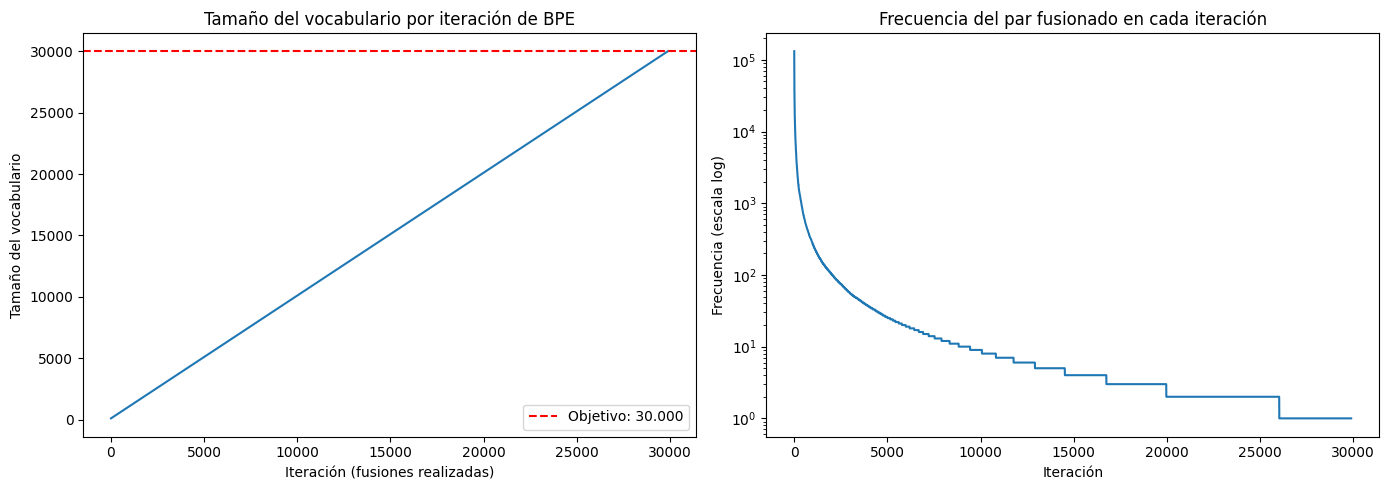

Iteración      0 -> vocabulario    102 | frecuencia del par fusionado: -
Iteración   1000 -> vocabulario   1102 | frecuencia del par fusionado: 266
Iteración   5000 -> vocabulario   5102 | frecuencia del par fusionado: 26
Iteración  10000 -> vocabulario  10102 | frecuencia del par fusionado: 9
Iteración  20000 -> vocabulario  20102 | frecuencia del par fusionado: 2
Iteración  29898 -> vocabulario  30000 | frecuencia del par fusionado: 1

Primeras 15 fusiones: ['e_', 's_', 'th', 't_', 'd_', 'in', 'er', 'y_', 'an', '._', 'the_', 'o_', ',_', 'on', 'en']
Últimas 15 fusiones:  ['corrid', 'corridors_', 'corrugated_', 'corrupting_', 'corsaut_', 'corseted_', 'cortner_', 'cosmetic', 'cosmeticians_', 'cosmos_', 'costello_', "costner's_", 'cottages_', 'cougar_', 'coule']


In [8]:
hist_iter, hist_vocab, hist_freq = zip(*simple_tokenizer.history)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(hist_iter, hist_vocab)
axes[0].axhline(simple_tokenizer.target_vocab_size, color='red', ls='--', label='Objetivo: 30.000')
axes[0].set_title('Tamaño del vocabulario por iteración de BPE')
axes[0].set_xlabel('Iteración (fusiones realizadas)')
axes[0].set_ylabel('Tamaño del vocabulario')
axes[0].legend()

axes[1].plot(hist_iter[1:], hist_freq[1:])
axes[1].set_yscale('log')
axes[1].set_title('Frecuencia del par fusionado en cada iteración')
axes[1].set_xlabel('Iteración')
axes[1].set_ylabel('Frecuencia (escala log)')
plt.tight_layout()
plt.show()

for it in [0, 1000, 5000, 10000, 20000, len(hist_iter) - 1]:
    freq = hist_freq[it] if hist_freq[it] is not None else '-'
    print(f"Iteración {hist_iter[it]:>6} -> vocabulario {hist_vocab[it]:>6} | frecuencia del par fusionado: {freq}")

first_tokens = [simple_tokenizer.merges[p] for p in list(simple_tokenizer.merges)[:15]]
last_tokens = [simple_tokenizer.merges[p] for p in list(simple_tokenizer.merges)[-15:]]
print(f"\nPrimeras 15 fusiones: {first_tokens}")
print(f"Últimas 15 fusiones:  {last_tokens}")

### Prueba del Tokenizador

Verificaremos que el tokenizador funciona correctamente codificando y decodificando un texto de ejemplo.

In [9]:
print("Ejemplo de codificación:")
print(simple_tokenizer.encode("The movie was maravilloso"))
print("\nEjemplo de decodificación:")
print(simple_tokenizer.decode(simple_tokenizer.encode("The movie was maravilloso")))
print("\nFragmentos:")
print([simple_tokenizer.reverse_vocab[i] for i in simple_tokenizer.encode("The movie was maravilloso") if i != 0])

Ejemplo de codificación:
[112, 188, 184, 493, 769, 136, 334, 229, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

Ejemplo de decodificación:
the movie was maravilloso [PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD][PAD]

In [10]:
print(f"Imprimir 15 de la totalidad del vocabulario de tamaño {simple_tokenizer.vocab_size}")
for idx, key in enumerate(simple_tokenizer.vocab):
    print(f"palabra o fragmento correspondiente '{key}' con su token {simple_tokenizer.vocab[key]}")
    if idx == 15:
        break

Imprimir 15 de la totalidad del vocabulario de tamaño 30000
palabra o fragmento correspondiente '[PAD]' con su token 0
palabra o fragmento correspondiente '[UNK]' con su token 1
palabra o fragmento correspondiente 'i' con su token 2
palabra o fragmento correspondiente '_' con su token 3
palabra o fragmento correspondiente 'r' con su token 4
palabra o fragmento correspondiente 'e' con su token 5
palabra o fragmento correspondiente 'n' con su token 6
palabra o fragmento correspondiente 't' con su token 7
palabra o fragmento correspondiente 'd' con su token 8
palabra o fragmento correspondiente 'a' con su token 9
palabra o fragmento correspondiente 'm' con su token 10
palabra o fragmento correspondiente 'c' con su token 11
palabra o fragmento correspondiente 'u' con su token 12
palabra o fragmento correspondiente 'o' con su token 13
palabra o fragmento correspondiente 's' con su token 14
palabra o fragmento correspondiente '-' con su token 15


## Preparación del Conjunto de Datos

Para nuestra ejecución, utilizaremos el dataset completo con 50.000 textos, ya que reducirlos a 1500, si bien resultaba en una ejecución más rápida, terminó disminuyendo la calidad y la precisión de los modelos finales.

Crearemos los conjuntos de entrenamiento, validación y prueba.

In [11]:
# Implementación del conjunto de datos IMDB
class IMDBDataset(Dataset):
    def __init__(self, tokenizer, max_length=128, seed=42):
        dataset = load_dataset('stanfordnlp/imdb')
        texts = list(dataset['train']['text']) + list(dataset['test']['text'])
        labels = list(dataset['train']['label']) + list(dataset['test']['label'])
        data = list(zip(texts, labels))
        random.Random(seed).shuffle(data)
        self.texts, self.labels = zip(*data)
        self.texts = self.texts[:50000]
        self.labels = self.labels[:50000]
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]
        inputs = self.tokenizer.encode(text, max_length=self.max_length)
        return torch.tensor(inputs, dtype=torch.long), label

# longitud de secuencia
max_length = 128
dataset = IMDBDataset(simple_tokenizer, max_length=max_length)

# Dividir el conjunto de datos en conjuntos de entrenamiento, validación y prueba
train_size = 26000
val_size = 6000
test_size = 18000
train_dataset, val_dataset, test_dataset = random_split(dataset, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(random_seed))

# DataLoader para batchear
g = torch.Generator()
g.manual_seed(random_seed)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True,generator = g)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

print(f"Tamaños de los conjuntos - Entrenamiento: {len(train_dataset)}, Validación: {len(val_dataset)}, Prueba: {len(test_dataset)}")

Tamaños de los conjuntos - Entrenamiento: 26000, Validación: 6000, Prueba: 18000


## Modelo

### 2: Mecanismo de Atención

- [] Capa de atención unidireccional **SingleHeadAttention** con matrices de Query, Key y Value $Q_q, Q_k, Q_v$ (libro capítulo 12.2)
- [] **Ajustado** Punto de dot producto de escala (libro capítulo 12.3.2)

In [13]:
class ScaledDotProductAttention(nn.Module):
    """
    Implementación de la atención unidireccional escalada por punto de escala,
    utilizada en las transformadoras.

    - Utiliza la función dot producto escalada para calcular los pesos de atención.
    - Aplica la función softmax para obtener las probabilidades de atención.
    - Multiplica las probabilidades de atención con el valor correspondiente para obtener el output.
    """
    def __init__(self, dim_model):
        super(ScaledDotProductAttention, self).__init__()
        # Factor de escala sqrt(D_q) del libro (cap. 12.3.2)
        self.scale = math.sqrt(dim_model)

    def forward(self, query, key, value, mask=None):
        """
        Procesar los inputs y obtener el output.

        - Calcula las matrices de dot producto entre query y key.
        - Divide las matrices de dot producto por la escala.
        - Aplica la función softmax para obtener las probabilidades de atención.
        - Multiplica las probabilidades de atención con el valor correspondiente para obtener el output.

        Parámetros:
            query, key, value (tensor): (..., N, D)
            mask (tensor bool, opcional): True en las posiciones que se pueden atender,
                con forma que se pueda transmitir (broadcast) a (..., N, N).

        Returns:
            output (tensor): El output de la capa de atención.
            attn_weights (tensor): Las probabilidades de atención.
        """
        scores = torch.matmul(query, key.transpose(-2, -1)) / self.scale
        if mask is not None:
            # Valor muy negativo (no -inf) para no generar NaN si una fila queda sin tokens válidos
            scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)
        attn_weights = F.softmax(scores, dim=-1)
        output = torch.matmul(attn_weights, value)
        return output, attn_weights

class SingleHeadAttention(nn.Module):
    """
    Implementación de la atención unidireccional con varias capas lineales,
    utilizada en las transformadoras.

    - Utiliza varias capas lineales para calcular las matrices de query, key y value.
    - Aplica la capa de atención escalada por punto de escala para obtener las probabilidades de atención.
    - Multiplica las probabilidades de atención con el valor correspondiente para obtener el output final.
    """
    def __init__(self, dim_model):
        super(SingleHeadAttention, self).__init__()
        # Matrices Omega_q, Omega_k, Omega_v (con sus sesgos beta) del libro
        self.W_q = nn.Linear(dim_model, dim_model)
        self.W_k = nn.Linear(dim_model, dim_model)
        self.W_v = nn.Linear(dim_model, dim_model)
        self.attention = ScaledDotProductAttention(dim_model)
        self.attn_weights = None  # últimos pesos de atención, para inspección

    def forward(self, x, mask=None):
        """
        Procesar los inputs y obtener el output.

        - Calcula las matrices de query, key y value utilizando varias capas lineales.
        - Aplica la capa de atención escalada por punto de escala para obtener las probabilidades de atención.
        - Multiplica las probabilidades de atención con el valor correspondiente para obtener el output final.

        Parámetros:
            x (tensor): (batch, N, dim_model)
            mask (tensor bool, opcional): (batch, N), True en los tokens reales y False en [PAD].

        Returns:
            output (tensor): El output final de la capa de atención.
        """
        query, key, value = self.W_q(x), self.W_k(x), self.W_v(x)
        if mask is not None:
            mask = mask[:, None, :]  # (batch, 1, N): la misma máscara de keys para cada query
        output, attn_weights = self.attention(query, key, value, mask)
        self.attn_weights = attn_weights.detach()
        return output

class MultiHeadAttention(nn.Module):
    """
    Atención multi-cabeza (libro cap. 12.3.3): H cabezas de dimensión D/H calculadas en paralelo,
    concatenadas y combinadas con una proyección de salida Omega_c.
    """
    def __init__(self, dim_model, num_heads):
        super(MultiHeadAttention, self).__init__()
        assert dim_model % num_heads == 0, "dim_model debe ser divisible por num_heads"
        self.num_heads = num_heads
        self.dim_head = dim_model // num_heads
        self.W_q = nn.Linear(dim_model, dim_model)
        self.W_k = nn.Linear(dim_model, dim_model)
        self.W_v = nn.Linear(dim_model, dim_model)
        self.W_o = nn.Linear(dim_model, dim_model)
        self.attention = ScaledDotProductAttention(self.dim_head)
        self.attn_weights = None

    def _split_heads(self, t):
        batch_size, seq_len, _ = t.shape
        return t.view(batch_size, seq_len, self.num_heads, self.dim_head).transpose(1, 2)

    def forward(self, x, mask=None):
        batch_size, seq_len, dim_model = x.shape
        query = self._split_heads(self.W_q(x))  # (batch, H, N, D/H)
        key = self._split_heads(self.W_k(x))
        value = self._split_heads(self.W_v(x))
        if mask is not None:
            mask = mask[:, None, None, :]  # (batch, 1, 1, N)
        output, attn_weights = self.attention(query, key, value, mask)
        self.attn_weights = attn_weights.detach()
        output = output.transpose(1, 2).reshape(batch_size, seq_len, dim_model)
        return self.W_o(output)

### 3: Capa del Transformer

- [x] Unir los elementos de la capa SingleHeadAttention, Block de normalización por capa (nn.LayerNorm) y el bloque de forward feedforward (nn.Linear) con una capa de normalización final (libro capítulo 12.4)
- [x] No olvidar las conexiones residuales

En general, se recomienda utilizar ReLU y además técnicas de regularización para mejorar la generalización del modelo a los datos de prueba (como Dropout).

Se implementa la versión del libro (post-LN), donde cada subcapa suma su salida a la entrada (conexión residual)
y luego normaliza

In [15]:
class TransformerEncoderLayer(nn.Module):
    """
    Una capa única en la arquitectura del codificador de transformer.

    Esta clase define un paso adelante que aplica atención autoregresa, seguido de dos capas lineales y normalización de capa.
    """
    def __init__(self, dim_model, dim_feedforward, num_heads=1, dropout=0.1):
        super(TransformerEncoderLayer, self).__init__()
        if num_heads == 1:
            self.self_attn = SingleHeadAttention(dim_model)
        else:
            self.self_attn = MultiHeadAttention(dim_model, num_heads)
        self.norm1 = nn.LayerNorm(dim_model)
        self.feedforward = nn.Sequential(
            nn.Linear(dim_model, dim_feedforward),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(dim_feedforward, dim_model),
        )
        self.norm2 = nn.LayerNorm(dim_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, src, mask=None):
        """
        Paso adelante a través de la capa del codificador de transformer.

        Parámetros:
            src (Tensor): Tensor de entrada a ser procesado por la capa, torch.Size([8, 128, 32])
            mask (Tensor bool, opcional): (batch, N), True en los tokens reales y False en [PAD].

        Regresa:
            Tensor: Tensor de salida después de aplicar la atención autoregresa y el FFN.
        """
        # 1) Auto-atención + conexión residual + LayerNorm
        src = self.norm1(src + self.dropout1(self.self_attn(src, mask)))
        # 2) Feed-forward por token + conexión residual + LayerNorm final
        src = self.norm2(src + self.dropout2(self.feedforward(src)))
        return src

### Arquitectura del Modelo

El **SentimentAnalysisModel** básico se proporciona. Este modelo combina todos los componentes anteriores para crear un clasificador de sentimientos.

In [16]:
class SentimentAnalysisModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes):
        super(SentimentAnalysisModel, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.encoder = TransformerEncoderLayer(embed_dim, hidden_dim)
        self.fc = nn.Linear(embed_dim, num_classes)

    def forward(self, src):
        src = self.embedding(src)
        encoded_output = self.encoder(src)
        pooled_output = encoded_output.mean(dim=1)
        return self.fc(pooled_output)

# Puedes experimentar con diferentes parámetros hiperbásicos, como la embedding o el dimensión oculta.
# Tal como puedes ajustar los parámetros de aprendizaje para mejorar el rendimiento del modelo.
embed_dim = 32
hidden_dim = 128
num_classes = 2
vocab_size = simple_tokenizer.vocab_size
model = SentimentAnalysisModel(vocab_size, embed_dim, hidden_dim, num_classes)

# Reiniciar semillas para garantizar inicialización de pesos y entrenamiento idénticos
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

# Test with synthetic data
fake_data = torch.randint(0, vocab_size, (8, max_length))
fake_output = model(fake_data)
assert fake_output.shape == (8, num_classes), "Output shape is incorrect"
print(f"Modelo creado exitosamente. Shape de salida: {fake_output.shape}")
model

Modelo creado exitosamente. Shape de salida: torch.Size([8, 2])


SentimentAnalysisModel(
  (embedding): Embedding(30000, 32)
  (encoder): TransformerEncoderLayer(
    (self_attn): SingleHeadAttention(
      (W_q): Linear(in_features=32, out_features=32, bias=True)
      (W_k): Linear(in_features=32, out_features=32, bias=True)
      (W_v): Linear(in_features=32, out_features=32, bias=True)
      (attention): ScaledDotProductAttention()
    )
    (norm1): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    (feedforward): Sequential(
      (0): Linear(in_features=32, out_features=128, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=128, out_features=32, bias=True)
    )
    (norm2): LayerNorm((32,), eps=1e-05, elementwise_affine=True)
    (dropout1): Dropout(p=0.1, inplace=False)
    (dropout2): Dropout(p=0.1, inplace=False)
  )
  (fc): Linear(in_features=32, out_features=2, bias=True)
)

### Modelo mejorado

`TransformerClassifier` agrega al modelo provisto: codificación posicional sinusoidal (cap. 12.3.1), máscara de
padding en la atención y en el promedio final, varias capas y cabezas, y embeddings inicializados con desviación
0,1 (la posición se escala igual). Se usa para comparar tamaños y en el bonus.

In [17]:
def sinusoidal_encoding(max_length, dim):
    """Codificación posicional fija con senos y cosenos de distintas frecuencias."""
    position = torch.arange(max_length).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, dim, 2) * (-math.log(10000.0) / dim))
    encoding = torch.zeros(max_length, dim)
    encoding[:, 0::2] = torch.sin(position * div_term)
    encoding[:, 1::2] = torch.cos(position * div_term)
    return encoding


class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_classes,
                 num_layers=1, num_heads=1, max_length=512, dropout=0.1, embed_init_std=0.1):
        super(TransformerClassifier, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        # Inicialización pequeña (por defecto PyTorch usa N(0, 1)): con pocos datos, los embeddings de palabras
        # poco vistas quedan cerca de cero en vez de aportar ruido grande al promedio final
        nn.init.normal_(self.embedding.weight, std=embed_init_std)
        with torch.no_grad():
            self.embedding.weight[0].zero_()
        # Posición sinusoidal escalada a la misma magnitud que los embeddings, para no tapar la identidad del token
        self.register_buffer('positional_encoding', embed_init_std * sinusoidal_encoding(max_length, embed_dim))
        self.dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList([
            TransformerEncoderLayer(embed_dim, hidden_dim, num_heads=num_heads, dropout=dropout)
            for _ in range(num_layers)
        ])
        self.fc = nn.Linear(embed_dim, num_classes)

    def forward(self, src):
        mask = src != 0  # True en tokens reales, False en [PAD]
        x = self.dropout(self.embedding(src) + self.positional_encoding[:src.size(1)])
        for layer in self.layers:
            x = layer(x, mask)
        # Promedio solo sobre los tokens reales
        mask_f = mask.unsqueeze(-1).float()
        pooled = (x * mask_f).sum(dim=1) / mask_f.sum(dim=1).clamp(min=1)
        return self.fc(self.dropout(pooled))


def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    embedding = model.embedding.weight.numel()
    return total, total - embedding

# Reiniciar semillas para garantizar inicialización de pesos y entrenamiento idénticos
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

test_model = TransformerClassifier(vocab_size, 64, 256, num_classes, num_layers=2, num_heads=4)
assert test_model(fake_data).shape == (8, num_classes), "Output shape is incorrect"
print(f"TransformerClassifier OK. Shape de salida: {test_model(fake_data).shape}")
total, sin_embedding = count_parameters(model)
print(f"Parámetros del modelo base: {total:,} (sin la tabla de embeddings: {sin_embedding:,})")
del test_model

TransformerClassifier OK. Shape de salida: torch.Size([8, 2])
Parámetros del modelo base: 971,714 (sin la tabla de embeddings: 11,714)


## Fase de Entrenamiento

### 4: Entrenamiento

- [] Implementar el mecanismo de detección temprana o otra monitoreo del progreso de aprendizaje
- [] Experimentar con tamaños más grandes de modelos y comparar el rendimiento obtenido con la cantidad de parámetros requeridos

Epoch:  1 | Training Loss: 0.6062, Training Acc: 64.45% | Validation Loss: 0.4740, Validation Accuracy: 77.38%  <- mejor
Epoch:  2 | Training Loss: 0.4099, Training Acc: 81.36% | Validation Loss: 0.4016, Validation Accuracy: 81.43%  <- mejor
Epoch:  3 | Training Loss: 0.3182, Training Acc: 86.67% | Validation Loss: 0.3956, Validation Accuracy: 82.67%  <- mejor
Epoch:  4 | Training Loss: 0.2533, Training Acc: 89.94% | Validation Loss: 0.4287, Validation Accuracy: 82.70%  <- mejor
Epoch:  5 | Training Loss: 0.2055, Training Acc: 92.27% | Validation Loss: 0.4795, Validation Accuracy: 82.88%  <- mejor
Epoch:  6 | Training Loss: 0.1642, Training Acc: 94.18% | Validation Loss: 0.5710, Validation Accuracy: 82.38%
Epoch:  7 | Training Loss: 0.1300, Training Acc: 95.87% | Validation Loss: 0.6987, Validation Accuracy: 82.20%
Epoch:  8 | Training Loss: 0.1009, Training Acc: 97.00% | Validation Loss: 0.8338, Validation Accuracy: 81.77%
Epoch:  9 | Training Loss: 0.0795, Training Acc: 97.82% | Vali

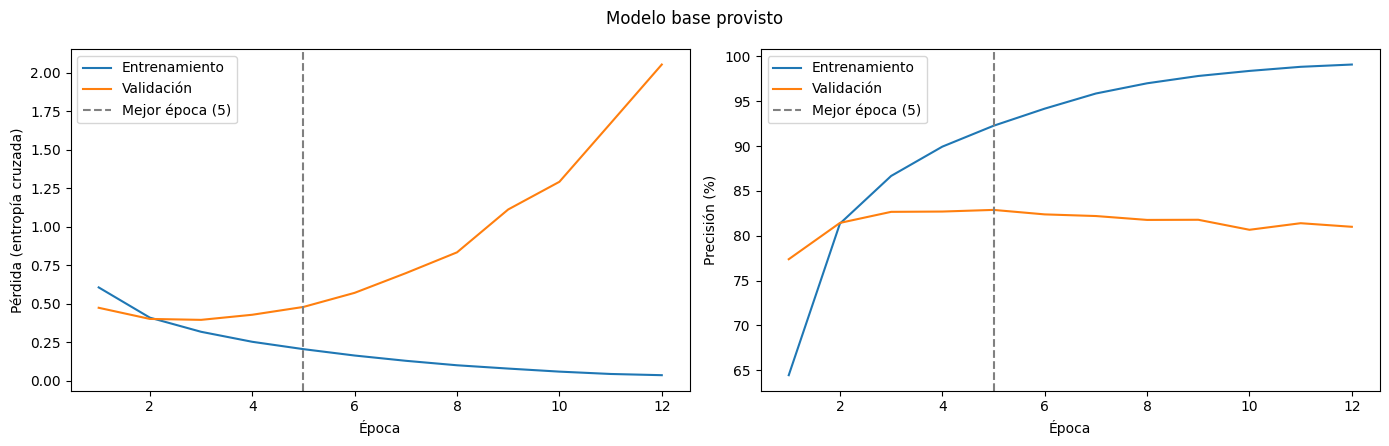

In [18]:
criterion = nn.CrossEntropyLoss()
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

def evaluate(model, loader):
    """Devuelve (pérdida promedio, precisión %) del modelo sobre un DataLoader."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for batch_texts, batch_labels in loader:
            batch_texts, batch_labels = batch_texts.to(device), batch_labels.to(device)
            outputs = model(batch_texts)
            total_loss += criterion(outputs, batch_labels).item() * batch_labels.size(0)
            correct += (outputs.argmax(dim=1) == batch_labels).sum().item()
            total += batch_labels.size(0)
    return total_loss / total, 100 * correct / total


def train_model(model, train_loader, val_loader, epochs=40, lr=1e-3, weight_decay=0.01, patience=7,
                warmup_epochs=1, verbose=True):
    """Entrena con AdamW y early stopping sobre la precisión de validación (empates: menor pérdida).

    La tasa de aprendizaje sube linealmente desde ~0 hasta `lr` durante las primeras `warmup_epochs` épocas.
    Al terminar restaura los pesos de la mejor época y devuelve el historial de métricas.
    """
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    warmup_steps = max(1, warmup_epochs * len(train_loader))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: min(1.0, (step + 1) / warmup_steps))
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_score, best_epoch, best_state, bad_epochs = (-1.0, 0.0), 0, None, 0

    for epoch in range(epochs):
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for batch_texts, batch_labels in train_loader:
            batch_texts, batch_labels = batch_texts.to(device), batch_labels.to(device)
            optimizer.zero_grad()
            output = model(batch_texts)
            loss = criterion(output, batch_labels)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            total_loss += loss.item() * batch_labels.size(0)
            correct += (output.argmax(dim=1) == batch_labels).sum().item()
            total += batch_labels.size(0)

        val_loss, val_acc = evaluate(model, val_loader)
        for key, value in zip(history, (total_loss / total, 100 * correct / total, val_loss, val_acc)):
            history[key].append(value)

        score = (val_acc, -val_loss)
        improved = score > best_score
        if improved:
            best_score, best_epoch, bad_epochs = score, epoch + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad_epochs += 1
        if verbose:
            print(f"Epoch: {epoch+1:2d} | Training Loss: {history['train_loss'][-1]:.4f}, "
                  f"Training Acc: {history['train_acc'][-1]:.2f}% | "
                  f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_acc:.2f}%"
                  + ("  <- mejor" if improved else ""))
        if bad_epochs >= patience:
            print(f"Early stopping en la época {epoch+1}: la precisión de validación no mejora hace {patience} épocas.")
            break

    model.load_state_dict(best_state)
    history['best_epoch'] = best_epoch
    print(f"Se restauran los pesos de la época {best_epoch}: Validation Loss {history['val_loss'][best_epoch - 1]:.4f}, "
          f"Validation Accuracy {history['val_acc'][best_epoch - 1]:.2f}%")
    return history


def plot_history(history, title):
    epochs_range = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(epochs_range, history['train_loss'], label='Entrenamiento')
    axes[0].plot(epochs_range, history['val_loss'], label='Validación')
    axes[0].set_ylabel('Pérdida (entropía cruzada)')
    axes[1].plot(epochs_range, history['train_acc'], label='Entrenamiento')
    axes[1].plot(epochs_range, history['val_acc'], label='Validación')
    axes[1].set_ylabel('Precisión (%)')
    for ax in axes:
        ax.axvline(history['best_epoch'], color='gray', ls='--', label=f"Mejor época ({history['best_epoch']})")
        ax.set_xlabel('Época')
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

# Reiniciar semillas para garantizar inicialización de pesos y entrenamiento idénticos
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

# Modelo base provisto (embed_dim=32, hidden_dim=128, 1 capa, 1 cabeza)
history_base = train_model(model, train_loader, val_loader, epochs=40, lr=1e-3)
plot_history(history_base, 'Modelo base provisto')

**Modelo base.** La mejor precisión de validación es 82,9% (época 5). Después el entrenamiento sigue subiendo
(99,1% en la época 12) mientras la validación baja (81,0% en la época 12): sobreajuste. El early stopping se
detiene en la época 12 y restaura la 5.

### Comparación de tamaños de modelo

Mismo protocolo para todos (`max_length = 128`, batch 16, dropout 0,3, *weight decay* 0,1, early stopping). El
mejor se elige por precisión de validación.

In [19]:
# Reiniciar semillas para garantizar inicialización de pesos y entrenamiento idénticos
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

size_configs = [
    # nombre, embed_dim, hidden_dim, num_layers, num_heads, lr
    ('XS', 32, 128, 1, 1, 1e-3),
    ('S', 64, 256, 2, 4, 1e-3),
    ('M', 128, 512, 2, 4, 1e-3),
    ('L', 256, 1024, 4, 8, 5e-4),
]
train_loader_16 = DataLoader(train_dataset, batch_size=16, shuffle=True)


def summarize(name, model, history, seconds, max_len, layers, heads, embed):
    total, sin_embedding = count_parameters(model)
    _, test_acc = evaluate(model, test_eval_loader if max_len == max_length else test_eval_loader_long)
    return {'modelo': name, 'max_length': max_len, 'embed_dim': embed, 'capas': layers, 'cabezas': heads,
            'parámetros': total, 'parámetros sin embedding': sin_embedding,
            'mejor época': history['best_epoch'], 'val_acc': history['val_acc'][history['best_epoch'] - 1],
            'test_acc': test_acc, 'tiempo (s)': round(seconds, 1)}


test_eval_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)
trained_models = {'Base (provisto)': model}
results = [summarize('Base (provisto)', model, history_base, float('nan'), max_length, 1, 1, embed_dim)]
histories = {'Base (provisto)': history_base}

for name, emb, hid, layers, heads, lr in size_configs:
    torch.manual_seed(random_seed)
    candidate = TransformerClassifier(vocab_size, emb, hid, num_classes, num_layers=layers,
                                      num_heads=heads, max_length=max_length, dropout=0.3)
    print(f"\n=== Modelo {name}: embed {emb}, FFN {hid}, {layers} capa(s), {heads} cabeza(s) ===")
    start = time.time()
    histories[name] = train_model(candidate, train_loader_16, val_loader, epochs=40, lr=lr, weight_decay=0.1,
                                  verbose=False)
    trained_models[name] = candidate
    results.append(summarize(name, candidate, histories[name], time.time() - start, max_length, layers, heads, emb))

results_df = pd.DataFrame(results).set_index('modelo')
results_df


=== Modelo XS: embed 32, FFN 128, 1 capa(s), 1 cabeza(s) ===
Early stopping en la época 9: la precisión de validación no mejora hace 7 épocas.
Se restauran los pesos de la época 2: Validation Loss 0.3799, Validation Accuracy 83.58%

=== Modelo S: embed 64, FFN 256, 2 capa(s), 4 cabeza(s) ===
Early stopping en la época 9: la precisión de validación no mejora hace 7 épocas.
Se restauran los pesos de la época 2: Validation Loss 0.3959, Validation Accuracy 82.88%

=== Modelo M: embed 128, FFN 512, 2 capa(s), 4 cabeza(s) ===
Early stopping en la época 10: la precisión de validación no mejora hace 7 épocas.
Se restauran los pesos de la época 3: Validation Loss 0.4189, Validation Accuracy 83.40%

=== Modelo L: embed 256, FFN 1024, 4 capa(s), 8 cabeza(s) ===
Early stopping en la época 9: la precisión de validación no mejora hace 7 épocas.
Se restauran los pesos de la época 2: Validation Loss 0.4619, Validation Accuracy 82.85%


,max_length,embed_dim,capas,cabezas,parámetros,parámetros sin embedding,mejor época,val_acc,test_acc,tiempo (s)
modelo,,,,,,,,,,
Base (provisto),128,32,1,1,971714,11714,5,82.883333,82.577778,NaN
XS,128,32,1,1,971714,11714,2,83.583333,83.594444,151.6
S,128,64,2,4,2020098,100098,2,82.883333,83.005556,204.7
M,128,128,2,4,4236802,396802,3,83.400000,83.372222,236.3
L,128,256,4,8,10839554,3159554,2,82.850000,82.927778,448.9


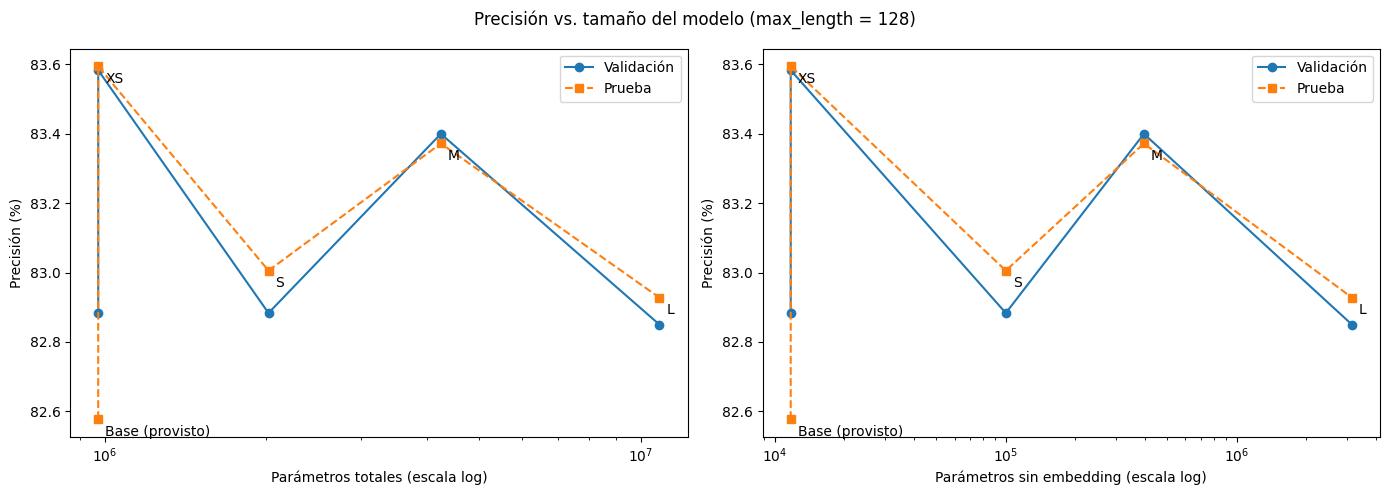

Mejor modelo por validación: XS


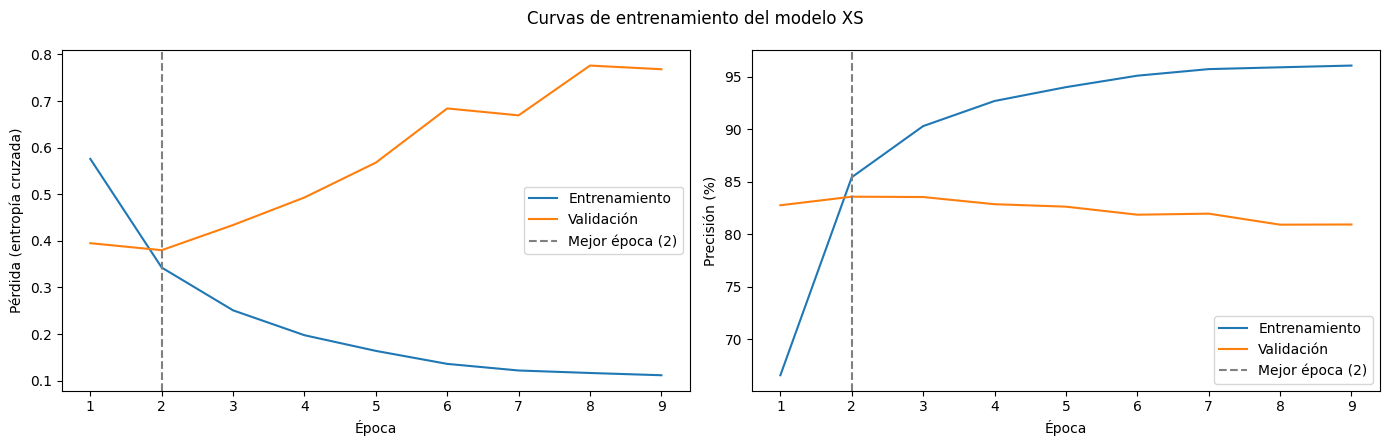

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, column, xlabel in [(axes[0], 'parámetros', 'Parámetros totales (escala log)'),
                           (axes[1], 'parámetros sin embedding', 'Parámetros sin embedding (escala log)')]:
    ax.plot(results_df[column], results_df['val_acc'], 'o-', label='Validación')
    ax.plot(results_df[column], results_df['test_acc'], 's--', label='Prueba')
    for name, row in results_df.iterrows():
        ax.annotate(name, (row[column], row['test_acc']), textcoords='offset points', xytext=(5, -12))
    ax.set_xscale('log')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Precisión (%)')
    ax.legend()
fig.suptitle('Precisión vs. tamaño del modelo (max_length = 128)')
plt.tight_layout()
plt.show()

best_size_name = results_df['val_acc'].idxmax()
print(f"Mejor modelo por validación: {best_size_name}")
plot_history(histories[best_size_name], f'Curvas de entrenamiento del modelo {best_size_name}')

**Resultado.** XS es el mejor en validación (83,6%) y en prueba (83,6%), por encima del modelo base (82,6%) y de
S, M y L (83,0%, 83,4% y 82,9%), aunque L tiene unas 270 veces más parámetros sin contar embeddings. La precisión
no crece con el tamaño: XS ya sobreajusta desde la época 2 (su pérdida de validación sube de 0,38 a ~0,78 en la
época 8), así que más capacidad no ayuda con 26.000 reseñas y 128 fragmentos. El tiempo sí crece (152 s para XS
y 449 s para L en la T4); el límite es el contexto (ver bonus).

## Análisis de Resultados

### 5: Evaluación en el Conjunto de Test

- [x] Comparar el rendimiento del modelo con muestras de prueba de diferentes longitudes
- [ ] Bonus: alcanzar una precisión superior al 90%. Es posible que debas incrementar el numero de parámetros y que debas implementar la atención múltiple AutoAtención y multicapa para lograr esto (libro capítulo 12.3.3). *(88,3% en prueba; no se alcanzó el 90%.)*

Modelo base provisto -> Test Accuracy: 82.58%

              precision    recall  f1-score   support

    Negativo      0.806     0.861     0.833      9070
    Positivo      0.848     0.790     0.818      8930

    accuracy                          0.826     18000
   macro avg      0.827     0.826     0.825     18000
weighted avg      0.827     0.826     0.826     18000



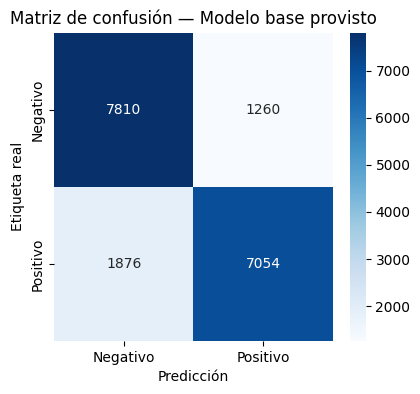

Modelo XS -> Test Accuracy: 83.59%

              precision    recall  f1-score   support

    Negativo      0.809     0.882     0.844      9070
    Positivo      0.868     0.789     0.827      8930

    accuracy                          0.836     18000
   macro avg      0.839     0.836     0.835     18000
weighted avg      0.839     0.836     0.836     18000



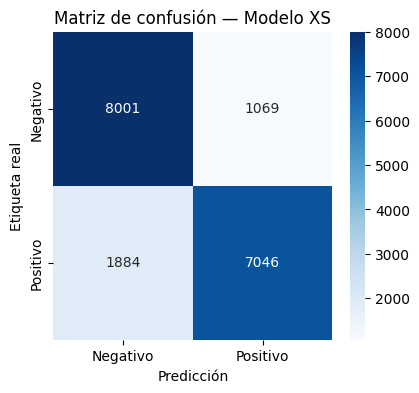

In [21]:
from sklearn.metrics import confusion_matrix, classification_report


def predict_loader(model, loader):
    """Devuelve etiquetas reales, predicciones y probabilidad de 'Positivo' para todo el loader."""
    model.eval()
    y_true, y_pred, p_pos = [], [], []
    with torch.no_grad():
        for batch_texts, batch_labels in loader:
            probs = F.softmax(model(batch_texts.to(device)), dim=1).cpu()
            y_true.extend(batch_labels.tolist())
            y_pred.extend(probs.argmax(dim=1).tolist())
            p_pos.extend(probs[:, 1].tolist())
    return np.array(y_true), np.array(y_pred), np.array(p_pos)


def show_test_results(model, loader, title):
    y_true, y_pred, p_pos = predict_loader(model, loader)
    print(f'{title} -> Test Accuracy: {100 * (y_true == y_pred).mean():.2f}%\n')
    print(classification_report(y_true, y_pred, target_names=['Negativo', 'Positivo'], digits=3))
    cm = confusion_matrix(y_true, y_pred)  # filas: etiqueta real, columnas: predicción
    plt.figure(figsize=(4.5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Negativo', 'Positivo'], yticklabels=['Negativo', 'Positivo'])
    plt.xlabel('Predicción')
    plt.ylabel('Etiqueta real')
    plt.title(f'Matriz de confusión — {title}')
    plt.show()
    return y_true, y_pred, p_pos


# Test loop (el test_loader original, batch_size=1)
y_true_base, y_pred_base, p_base = show_test_results(model, test_loader, 'Modelo base provisto')
best_size_model = trained_models[best_size_name]
y_true_best, y_pred_best, p_best = show_test_results(best_size_model, test_loader, f'Modelo {best_size_name}')

### Precisión según la longitud de la reseña

Cuartiles de las reseñas de prueba según su número de palabras; para cada uno, la precisión y el % de reseñas
truncadas con `max_length`.

--- Base (provisto) (max_length = 128) ---
                      n  precisión %  truncadas %
tramo                                            
6–126 palabras     4509         87.2         43.2
127–174 palabras   4501         85.6        100.0
175–283 palabras   4493         81.4        100.0
284–1839 palabras  4497         76.0        100.0 

--- XS (max_length = 128) ---
                      n  precisión %  truncadas %
tramo                                            
6–126 palabras     4509         87.9         43.2
127–174 palabras   4501         86.4        100.0
175–283 palabras   4493         82.3        100.0
284–1839 palabras  4497         77.7        100.0 



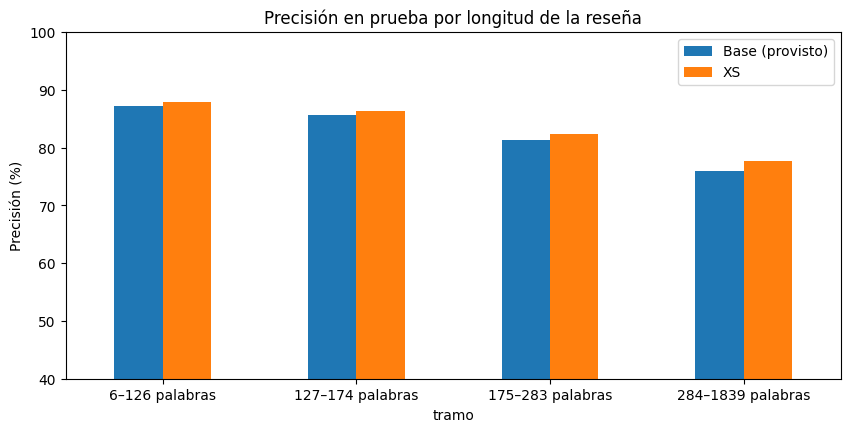

In [22]:
test_texts = [dataset.texts[i] for i in test_dataset.indices]
test_words = np.array([word_count(t) for t in test_texts])
test_subwords = np.array([simple_tokenizer.count_subwords(t) for t in test_texts])
length_bins = pd.qcut(test_words, q=4)
length_bins = length_bins.rename_categories(
    [f'{int(max(c.left, 0)) + 1}–{int(c.right)} palabras' for c in length_bins.categories])


def accuracy_by_length(y_true, y_pred, max_len):
    df = pd.DataFrame({'tramo': length_bins, 'correcto': y_true == y_pred, 'truncada': test_subwords > max_len})
    table = df.groupby('tramo', observed=True).agg(n=('correcto', 'size'), precision=('correcto', 'mean'),
                                                   truncadas=('truncada', 'mean'))
    table[['precision', 'truncadas']] *= 100
    return table.round(1)


length_tables = {
    'Base (provisto)': accuracy_by_length(y_true_base, y_pred_base, max_length),
    best_size_name: accuracy_by_length(y_true_best, y_pred_best, max_length),
}
for name, table in length_tables.items():
    print(f"--- {name} (max_length = {max_length}) ---")
    print(table.rename(columns={'precision': 'precisión %', 'truncadas': 'truncadas %'}), '\n')

pd.DataFrame({name: t['precision'] for name, t in length_tables.items()}).plot.bar(figsize=(10, 4.5), rot=0)
plt.ylabel('Precisión (%)')
plt.ylim(40, 100)
plt.title('Precisión en prueba por longitud de la reseña')
plt.show()

**Resultado.** Con 128 fragmentos la precisión baja con el largo: XS pasa de 87,9% (hasta 126 palabras) a 77,7%
(284 o más). Desde el segundo cuartil se trunca el 100% de las reseñas, así que el modelo no ve el final, donde
suele estar el veredicto.

### Bonus: atención multi-cabeza, varias capas y contexto largo

`TransformerClassifier` con 4 cabezas, 2 capas y `max_length = 512` (mismas particiones). La configuración se
eligió en pruebas preliminares con 1.500 reseñas.

Epoch:  1 | Training Loss: 0.5056, Training Acc: 72.12% | Validation Loss: 0.2950, Validation Accuracy: 87.78%  <- mejor
Epoch:  2 | Training Loss: 0.2748, Training Acc: 89.23% | Validation Loss: 0.2750, Validation Accuracy: 88.12%  <- mejor
Epoch:  3 | Training Loss: 0.1856, Training Acc: 93.36% | Validation Loss: 0.3510, Validation Accuracy: 87.88%
Epoch:  4 | Training Loss: 0.1313, Training Acc: 95.70% | Validation Loss: 0.3589, Validation Accuracy: 88.23%  <- mejor
Epoch:  5 | Training Loss: 0.1072, Training Acc: 96.68% | Validation Loss: 0.3783, Validation Accuracy: 87.38%
Epoch:  6 | Training Loss: 0.0913, Training Acc: 97.08% | Validation Loss: 0.5359, Validation Accuracy: 86.77%
Epoch:  7 | Training Loss: 0.0911, Training Acc: 97.25% | Validation Loss: 0.4677, Validation Accuracy: 86.75%
Epoch:  8 | Training Loss: 0.0830, Training Acc: 97.44% | Validation Loss: 0.5575, Validation Accuracy: 85.52%
Epoch:  9 | Training Loss: 0.0826, Training Acc: 97.46% | Validation Loss: 0.4998,

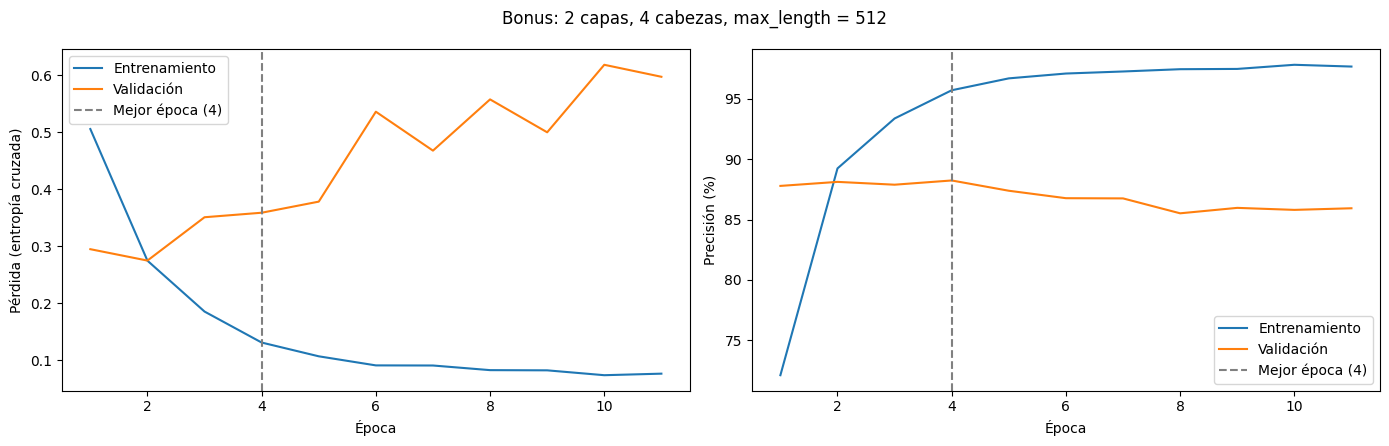

,max_length,embed_dim,capas,cabezas,parámetros,parámetros sin embedding,mejor época,val_acc,test_acc,tiempo (s)
modelo,,,,,,,,,,
Base (provisto),128,32,1,1,971714,11714,5,82.883333,82.577778,NaN
XS,128,32,1,1,971714,11714,2,83.583333,83.594444,151.6
S,128,64,2,4,2020098,100098,2,82.883333,83.005556,204.7
M,128,128,2,4,4236802,396802,3,83.400000,83.372222,236.3
L,128,256,4,8,10839554,3159554,2,82.850000,82.927778,448.9
Bonus,512,64,2,4,2020098,100098,4,88.233333,88.255556,543.9


In [23]:
max_length_long = 512
dataset_long = IMDBDataset(simple_tokenizer, max_length=max_length_long)
train_long, val_long, test_long = random_split(
    dataset_long, [train_size, val_size, test_size], generator=torch.Generator().manual_seed(random_seed))
assert test_long.indices == test_dataset.indices, "La partición de prueba debe ser la misma"

train_loader_long = DataLoader(train_long, batch_size=16, shuffle=True)
val_loader_long = DataLoader(val_long, batch_size=8, shuffle=False)
test_loader_long = DataLoader(test_long, batch_size=1, shuffle=False)
test_eval_loader_long = DataLoader(test_long, batch_size=64, shuffle=False)

bonus_config = dict(embed_dim=64, hidden_dim=256, num_layers=2, num_heads=4, dropout=0.3, lr=1e-3, weight_decay=0.1)
torch.manual_seed(random_seed)
bonus_model = TransformerClassifier(vocab_size, bonus_config['embed_dim'], bonus_config['hidden_dim'], num_classes,
                                    num_layers=bonus_config['num_layers'], num_heads=bonus_config['num_heads'],
                                    max_length=max_length_long, dropout=bonus_config['dropout'])
start = time.time()
history_bonus = train_model(bonus_model, train_loader_long, val_loader_long, epochs=40, lr=bonus_config['lr'],
                            weight_decay=bonus_config['weight_decay'])
bonus_seconds = time.time() - start
plot_history(history_bonus, f'Bonus: {bonus_config["num_layers"]} capas, {bonus_config["num_heads"]} cabezas, max_length = {max_length_long}')

results_df.loc['Bonus'] = pd.Series(summarize('Bonus', bonus_model, history_bonus, bonus_seconds, max_length_long,
                                              bonus_config['num_layers'], bonus_config['num_heads'],
                                              bonus_config['embed_dim'])).drop('modelo')
results_df

Bonus -> Test Accuracy: 88.26%

              precision    recall  f1-score   support

    Negativo      0.878     0.890     0.884      9070
    Positivo      0.887     0.875     0.881      8930

    accuracy                          0.883     18000
   macro avg      0.883     0.882     0.883     18000
weighted avg      0.883     0.883     0.883     18000



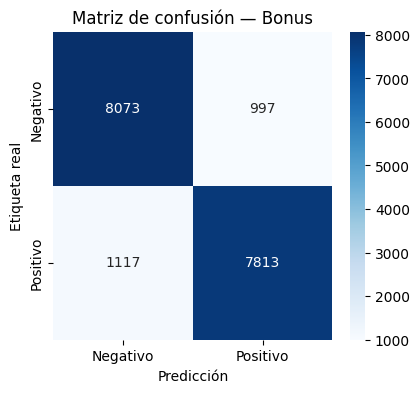

¿Supera el 90%? No (88.26%)

--- Bonus (max_length = 512) ---
                      n  precisión %  truncadas %
tramo                                            
6–126 palabras     4509         88.5          0.0
127–174 palabras   4501         89.1          0.0
175–283 palabras   4493         88.2          0.0
284–1839 palabras  4497         87.3         47.6


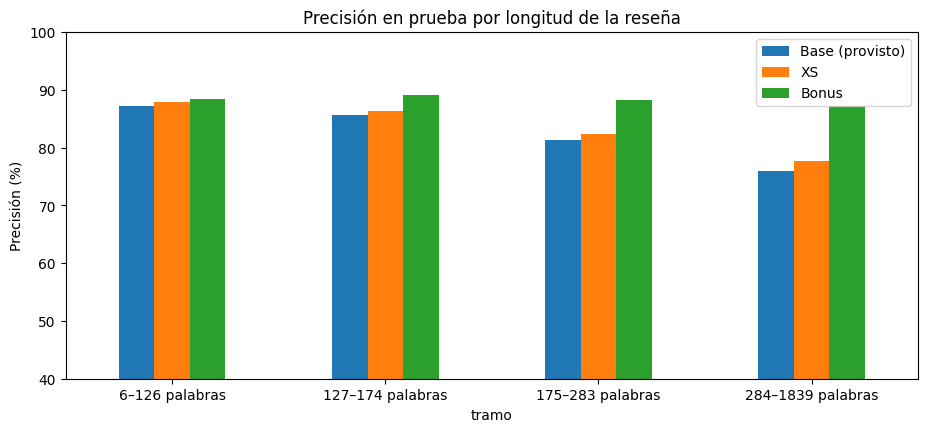

In [24]:
y_true_bonus, y_pred_bonus, p_bonus = show_test_results(bonus_model, test_loader_long, 'Bonus')
bonus_acc = 100 * (y_true_bonus == y_pred_bonus).mean()
print(f"¿Supera el 90%? {'Sí' if bonus_acc > 90 else 'No'} ({bonus_acc:.2f}%)")

length_tables['Bonus'] = accuracy_by_length(y_true_bonus, y_pred_bonus, max_length_long)
print(f"\n--- Bonus (max_length = {max_length_long}) ---")
print(length_tables['Bonus'].rename(columns={'precision': 'precisión %', 'truncadas': 'truncadas %'}))

pd.DataFrame({name: t['precision'] for name, t in length_tables.items()}).plot.bar(figsize=(11, 4.5), rot=0)
plt.ylabel('Precisión (%)')
plt.ylim(40, 100)
plt.title('Precisión en prueba por longitud de la reseña')
plt.show()

**Resultado: 88,3% en prueba (88,2% en validación). No llega al 90%.** Con el mismo tamaño que S, pasar de 128 a
512 fragmentos sube la prueba de 83,0% a 88,3%, y la precisión queda pareja en todos los largos (87,3–89,1%).
Desde la época 4 sobreajusta: el entrenamiento sube hasta 97,8% y la validación baja a 85,5–87,4%.

## Despliegue

### 6: Pruebas con Ejemplos Personalizados

- [x] Intenta crear nuevos ejemplos donde el modelo falla al clasificar correctamente el sentimiento.
- [x] Experimenta, describe y explica qué ocurre cuando intentas clasificar una crítica de cine en español utilizando tu modelo de transformador.

In [27]:
# Modelo final: el de mayor precisión de validación entre todos los entrenados
trained_models['Bonus'] = bonus_model
final_name = results_df['val_acc'].astype(float).idxmax()
final_model = trained_models[final_name]
final_max_length = int(results_df.loc[final_name, 'max_length'])
class_labels = {0: "Negative", 1: "Positive"}


def predict(review, model=None, max_len=None):
    """Clasifica una reseña y devuelve (etiqueta, probabilidad de 'Positive')."""
    model = model if model is not None else final_model
    max_len = max_len if max_len is not None else final_max_length
    inputs = simple_tokenizer.encode(review, max_length=max_len)
    inputs = torch.tensor([inputs], dtype=torch.long).to(device)
    model.eval()
    with torch.no_grad():
        probs = F.softmax(model(inputs), dim=1)[0].cpu()
    return class_labels[probs.argmax().item()], probs[1].item()


review = "The movie was amazing"
predicted_label, p_positive = predict(review)
print(f"The predicted class for the text '{review}' is: {predicted_label} (P(positive) = {p_positive:.2f})")

The predicted class for the text 'The movie was amazing' is: Positive (P(positive) = 1.00)


### Casos difíciles en inglés

In [28]:
custom_reviews = [
    # (reseña, etiqueta esperada, tipo de caso)
    ("The movie was amazing", "Positive", "simple"),
    ("An absolute masterpiece, the acting and the soundtrack were wonderful.", "Positive", "simple"),
    ("This was the worst film I have ever seen, a total waste of time.", "Negative", "simple"),
    ("The movie was not good at all.", "Negative", "negación"),
    ("I didn't hate it. Honestly, it is not bad at all.", "Positive", "doble negación"),
    ("Oh great, another two hours of my life I will never get back. Brilliant.", "Negative", "sarcasmo"),
    ("The actors were great and the photography was beautiful, but the story was so boring that I fell asleep.",
     "Negative", "contraste"),
    ("Everyone told me it was awful and I expected to hate it, but I loved every minute.", "Positive", "giro final"),
    ("Meh.", "Negative", "muy corta"),
    ("10/10", "Positive", "muy corta"),
]

rows = []
for text, expected, case in custom_reviews:
    predicted, p_positive = predict(text)
    rows.append({'reseña': text, 'caso': case, 'esperado': expected, 'predicho': predicted,
                 'P(positive)': round(p_positive, 3), 'correcto': '✓' if predicted == expected else '✗'})
custom_df = pd.DataFrame(rows)
print(f"Aciertos: {(custom_df['correcto'] == '✓').sum()} de {len(custom_df)}")
with pd.option_context('display.max_colwidth', 120):
    display(custom_df)

Aciertos: 6 de 10


,reseña,caso,esperado,predicho,P(positive),correcto
0,The movie was amazing,simple,Positive,Positive,0.996,✓
1,"An absolute masterpiece, the acting and the soundtrack were wonderful.",simple,Positive,Positive,0.996,✓
2,"This was the worst film I have ever seen, a total waste of time.",simple,Negative,Negative,0.004,✓
3,The movie was not good at all.,negación,Negative,Negative,0.105,✓
4,"I didn't hate it. Honestly, it is not bad at all.",doble negación,Positive,Negative,0.004,✗
5,"Oh great, another two hours of my life I will never get back. Brilliant.",sarcasmo,Negative,Positive,0.996,✗
6,"The actors were great and the photography was beautiful, but the story was so boring that I fell asleep.",contraste,Negative,Negative,0.008,✓
7,"Everyone told me it was awful and I expected to hate it, but I loved every minute.",giro final,Positive,Positive,0.953,✓
8,Meh.,muy corta,Negative,Positive,0.939,✗
9,10/10,muy corta,Positive,Negative,0.012,✗


**Resultado: 6 de 10.** Falla la doble negación ("I didn't hate it... not bad", P(positive) = 0,004), el sarcasmo
(0,996) y las dos reseñas de una palabra, que salen al revés ("Meh." 0,939; "10/10" 0,012). El modelo promedia
los fragmentos: no capta la ironía ni las negaciones compuestas, y un texto tan corto está fuera de lo que vio al
entrenar.

### Reseñas en español

In [29]:
spanish_reviews = [
    # (español, traducción al inglés, etiqueta esperada)
    ("La película fue maravillosa, la recomiendo totalmente.",
     "The movie was wonderful, I totally recommend it.", "Positive"),
    ("Una película excelente, con actuaciones brillantes y una historia emocionante.",
     "An excellent movie, with brilliant performances and an exciting story.", "Positive"),
    ("Me encantó, es la mejor película del año.",
     "I loved it, it is the best movie of the year.", "Positive"),
    ("Es una película horrible, aburrida y demasiado larga.",
     "It is a horrible movie, boring and way too long.", "Negative"),
    ("Pésima. Los actores son malísimos y el guion no tiene ningún sentido.",
     "Awful. The actors are terrible and the script makes no sense at all.", "Negative"),
    ("Una pérdida de tiempo y de dinero, no la recomiendo.",
     "A waste of time and money, I do not recommend it.", "Negative"),
]

rows = []
for spanish, english, expected in spanish_reviews:
    pred_es, p_es = predict(spanish)
    pred_en, p_en = predict(english)
    rows.append({'reseña en español': spanish, 'esperado': expected,
                 'pred. español': pred_es, 'P(pos) español': round(p_es, 3),
                 'pred. inglés': pred_en, 'P(pos) inglés': round(p_en, 3)})
spanish_df = pd.DataFrame(rows)
print(f"Aciertos en español: {(spanish_df['pred. español'] == spanish_df['esperado']).sum()} de {len(spanish_df)}")
print(f"Aciertos en inglés:  {(spanish_df['pred. inglés'] == spanish_df['esperado']).sum()} de {len(spanish_df)}")
with pd.option_context('display.max_colwidth', 80):
    display(spanish_df)


def segmentation_stats(sentences):
    words = [w for s in sentences for w in simple_tokenizer.tokenize(s)]
    pieces = [simple_tokenizer._apply_bpe_to_word(w) for w in words]
    n_pieces = sum(len(p) for p in pieces)
    n_unk = sum(tok not in simple_tokenizer.vocab for p in pieces for tok in p)
    whole = sum(len(p) == 1 for p in pieces)
    return {'fragmentos por palabra': round(n_pieces / len(words), 2),
            'palabras que son un solo fragmento %': round(100 * whole / len(words), 1),
            'fragmentos [UNK] %': round(100 * n_unk / n_pieces, 1)}


print()
print(pd.DataFrame({'español': segmentation_stats([s for s, _, _ in spanish_reviews]),
                    'inglés': segmentation_stats([e for _, e, _ in spanish_reviews])}))

for sentence in [spanish_reviews[0][0], spanish_reviews[0][1], spanish_reviews[4][0]]:
    ids = [i for i in simple_tokenizer.encode(sentence, max_length=64) if i != 0]
    print(f"\n{sentence}\n  -> {[simple_tokenizer.reverse_vocab[i] for i in ids]}")

Aciertos en español: 5 de 6
Aciertos en inglés:  6 de 6


,reseña en español,esperado,pred. español,P(pos) español,pred. inglés,P(pos) inglés
0,"La película fue maravillosa, la recomiendo totalmente.",Positive,Positive,0.988,Positive,0.996
1,"Una película excelente, con actuaciones brillantes y una historia emocionante.",Positive,Positive,0.994,Positive,0.996
2,"Me encantó, es la mejor película del año.",Positive,Positive,0.985,Positive,0.996
3,"Es una película horrible, aburrida y demasiado larga.",Negative,Negative,0.200,Negative,0.004
4,Pésima. Los actores son malísimos y el guion no tiene ningún sentido.,Negative,Positive,0.993,Negative,0.004
5,"Una pérdida de tiempo y de dinero, no la recomiendo.",Negative,Negative,0.010,Negative,0.004



                                      español  inglés
fragmentos por palabra                   2.09     1.0
palabras que son un solo fragmento %    55.20   100.0
fragmentos [UNK] %                       0.00     0.0

La película fue maravillosa, la recomiendo totalmente.
  -> ['la_', 'pel', 'í', 'cul', 'a_', 'fu', 'e_', 'mar', 'av', 'il', 'lo', 'sa_', ',_', 'la_', 're', 'com', 'i', 'en', 'do_', 'total', 'ment', 'e_', '._']

The movie was wonderful, I totally recommend it.
  -> ['the_', 'movie_', 'was_', 'wonderful_', ',_', 'i_', 'totally_', 'recommend_', 'it_', '._']

Pésima. Los actores son malísimos y el guion no tiene ningún sentido.
  -> ['p', 'é', 'sim', 'a_', '._', 'los_', 'act', 'ores_', 'son_', 'mal', 'í', 'si', 'mos_', 'y_', 'el_', 'gu', 'ion_', 'no_', 'ti', 'ene_', 'n', 'ing', 'ú', 'n_', 'senti', 'do_', '._']


**Resultado: 5 de 6 (inglés: 6 de 6).** BPE no genera `[UNK]`, pero parte el español en fragmentos sin
significado para el modelo: 2,09 fragmentos por palabra contra 1,0 en inglés (`maravillosa` →
`mar|av|il|lo|sa_`). Falla justo la reseña más clara ("Pésima... malísimos", P(positive) = 0,993). Con 6 ejemplos
el acierto no es concluyente.

## Conclusiones

Analiza los resultados obtenidos:

- ¿Qué tipo de reseñas fueron más difíciles de clasificar para el modelo? ¿A qué crees que se debe?
- ¿Qué mejoras podrías proponer para el modelo o el proceso de entrenamiento?
- ¿Qué sucede cuando pruebas el modelo con texto en español?

### Resumen (precisión en prueba)

| Modelo | 1.500 reseñas | 50.000 reseñas |
|---|---|---|
| Base provisto | 63,0% | 82,6% |
| Mejor tamaño por validación | 73,8% (M) | 83,6% (XS) |
| Bonus (2 capas, 4 cabezas, `max_length = 512`) | 79,0% | 88,3% |

**¿Qué reseñas fueron más difíciles?** Las largas, porque se truncan (XS baja de 87,9% a 77,7% del cuartil más
corto al más largo), y las que el modelo no puede resolver promediando palabras: sarcasmo, doble negación y
reseñas de una sola palabra. El modelo se comporta casi como una bolsa de palabras.

**¿Qué mejoras se pueden proponer?** Más contexto (pasar a 512 fragmentos fue lo que más ayudó: +5,3 puntos);
pre-entrenamiento y ajuste fino tipo BERT (cap. 12.6) o embeddings pre-entrenados; un token `[CLS]` o *pooling*
por atención en vez del promedio; más regularización o menos épocas, porque el bonus sobreajusta desde la época 4;
y entrenar el tokenizador con una muestra aleatoria (hoy usa las primeras 3.000 reseñas, todas negativas).

**¿Qué sucede con texto en español?** BPE no deja `[UNK]`, pero divide las palabras en fragmentos sin significado
para un modelo entrenado solo en inglés. Acierta 5 de 6, pero con tan pocos ejemplos no se puede concluir que
entienda español. Para eso habría que entrenar con datos en español o usar un modelo multilingüe (mBERT, XLM-R).